# Which unfamiliar tasks the moment estimator can take: labels from its error

The awareness layer sends each window to one of three controllers: the **spline** for familiar cyclic gait
(ID-safe), the **joint-moment estimator** for unfamiliar movement it can handle (OOD-safe), and **off** for
movement it cannot (OOD-dangerous). The split of the 22 unfamiliar tasks into OOD-safe and OOD-dangerous has so far
been set by hand (`nature_data.OOD_DANGEROUS_TASKS`: ball toss, step-ups, tug of war, sit-to-stand). This notebook
measures it instead, from the error of the estimator that was actually deployed in the Nature study:
`torque_estimated` in every `Exo.csv`, scored against the biological hip moment (notebook 01, section 5.5).

**Rule, fixed before any task was scored** (`ml/nature/estimator_labels.py`, checked by `test_estimator_labels.py`):

| step | rule |
|---|---|
| people | the seven Phase 3 participants who are not in Phase 1–2 (BT18–BT24), so never in the deployed estimator's training data |
| samples | in-task samples of each leg (its own activity flag), both legs pooled per person, moment and estimate both finite |
| score | per task and person, the RMSE of the estimate against the moment (Nm/kg, extension positive); a task's score is the mean over people |
| envelope | the largest task score among the four familiar tasks (normal, incline and weighted walking, stairs): the worst error the estimator runs with on movement the pipeline treats as normal |
| label | an unfamiliar task is **OOD-safe** at or below the envelope, **OOD-dangerous** above it; **near the boundary** when the participant-bootstrap 95% interval of (score − envelope) contains zero |

Context, not part of the rule: the **relative error** (RMSE divided by the RMS of the moment; at 1 the estimator
delivers torque no closer to the intended assistance than switching off would) and the **wrong-direction share**
(samples with |moment| ≥ 0.1 Nm/kg where the estimate has the opposite sign).

**A ceiling, not our estimator.** The deployed estimator used hip and knee encoders and thigh, shank and foot IMUs;
this project's fallback will see the hip encoder and thigh IMU only, so its errors will be larger and these labels
are the optimistic end.

## Findings at a glance

- **Only the ball toss is clearly worse than the estimator's familiar envelope.** Its RMSE is 0.279 Nm/kg (95%
  interval 0.252 to 0.309) against an envelope of 0.190 (stairs, 0.169 to 0.241); its difference from the envelope is
  positive in the whole interval.
- **The rule labels four tasks OOD-dangerous: ball toss, step-ups, cutting and lunges.** Against the provisional
  labels it moves sit-to-stand and tug of war to OOD-safe and cutting and lunges to OOD-dangerous. Eight of the 22
  unfamiliar tasks, all four changes among them, sit near the boundary: seven people cannot settle them, and
  adding the three returning participants flips tug of war, jump and tire run to OOD-dangerous.
- **Absolute error mostly measures how large the moment is.** Across the 26 tasks RMSE rises with the moment's size
  (Spearman 0.81) and relative error falls with it (−0.82). The tasks above the envelope are high-moment tasks on which
  the estimator is relatively accurate.
- **Against switching off, the estimator wins on every task.** Relative error is 0.25 to 0.56 on unfamiliar tasks and
  0.31 to 0.64 on familiar ones (1 would mean no better than off). By delivered-torque error, no unfamiliar task is
  worse for this estimator than familiar walking is.
- **The expected surprise did not appear in RMSE, but did in direction.** Push has one of the lowest RMSEs
  (0.115 Nm/kg), yet 11.9% of its samples above 0.1 Nm/kg are assisted the wrong way, second only to step-ups (13.5%);
  tug of war is at 5.2%. Stairs and weighted walking, both familiar, are at 10 to 11%.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'ml' / 'nature' / 'nature_data.py').exists())
for folder in ('ml/common', 'ml/nature'):
    if str(REPO / folder) not in sys.path:
        sys.path.insert(0, str(REPO / folder))
import nature_data as nt
import estimator_labels as el

pd.set_option('display.width', 200)
pd.set_option('display.max_rows', 40)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 9})
CLASS_C = {'ID-safe': '#287da8', 'OOD-safe': '#dd791a', 'OOD-dangerous': '#a32d2d'}   # as in the model notebooks; validated
FAMILIAR = nt.ID_SAFE_TASKS
FIG_DIR = Path.cwd() / 'figures'
FIG_DIR.mkdir(exist_ok = True)
SEED = 0

inv = nt.build_cache()
HELD_OUT = el.get_held_out_subjects(inv)
RETURNING = sorted(set(inv.loc[inv.phase == 'phase3', 'subject']) - set(HELD_OUT))
print(f'held-out people (never in the estimator\'s training data): {HELD_OUT}')
print(f'returning Phase 3 people (trained on in an earlier session; section 4 only): {RETURNING}')

held-out people (never in the estimator's training data): ['BT18', 'BT19', 'BT20', 'BT21', 'BT22', 'BT23', 'BT24']
returning Phase 3 people (trained on in an earlier session; section 4 only): ['BT01', 'BT02', 'BT13']


## 1. Samples

In [2]:
pairs = el.load_pairs(inv, HELD_OUT)
errors = el.get_person_task_errors(pairs)
cover = errors.pivot(index = 'task', columns = 'subject', values = 'samples').fillna(0) / nt.RATE_HZ / 60
print(f'{len(pairs):,} in-task samples (both legs) from {pairs.subject.nunique()} people and {pairs.task.nunique()} tasks')
print('minutes of in-task data per task and person (both legs):')
display(cover.round(1))

4,244,970 in-task samples (both legs) from 7 people and 26 tasks
minutes of in-task data per task and person (both legs):


subject,BT18,BT19,BT20,BT21,BT22,BT23,BT24
task,,,,,,,
ball_toss,0.7,0.6,0.6,0.6,0.8,0.6,0.6
curb_down,0.8,0.8,0.8,0.8,0.7,0.7,0.7
curb_up,0.8,1.0,0.8,0.9,0.8,0.9,0.8
cutting,1.0,1.3,1.3,1.1,1.0,1.1,1.2
dynamic_walk,2.6,2.6,2.7,2.6,2.6,2.7,2.7
incline_walk,2.7,2.7,2.7,2.7,2.7,2.7,2.6
jump,2.9,4.1,2.6,4.1,2.6,2.8,3.2
lift_weight,2.7,3.4,3.6,3.2,3.0,3.3,3.0
lunges,1.5,1.4,1.5,1.7,1.3,1.8,1.8


## 2. Error by task, and the boundary

In [3]:
table, env = el.get_task_table(errors, FAMILIAR, np.random.default_rng(SEED))
print(f"envelope: {env['envelope']:.3f} Nm/kg ({env['envelope_task']}; 95% interval {env['envelope_lo']:.3f} to {env['envelope_hi']:.3f})")
shown = pd.DataFrame({
    'label': table['label'] + np.where(table['near_boundary'], ' (near)', ''),
    'provisional': table['provisional'],
    'RMSE, Nm/kg': table['rmse'].map('{:.3f}'.format) + ' [' + table['rmse_lo'].map('{:.3f}'.format) + ', ' + table['rmse_hi'].map('{:.3f}'.format) + ']',
    'minus envelope, 95%': '[' + table['minus_envelope_lo'].map('{:+.3f}'.format) + ', ' + table['minus_envelope_hi'].map('{:+.3f}'.format) + ']',
    'RMS of moment': table['rms_moment'].round(3), 'relative error': table['relative_error'].round(2),
    'wrong direction, %': table['wrong_direction_pct'].round(1), 'people': table['people']})
display(shown)

envelope: 0.190 Nm/kg (stairs; 95% interval 0.169 to 0.241)


,label,provisional,"RMSE, Nm/kg","minus envelope, 95%",RMS of moment,relative error,"wrong direction, %",people
task,,,,,,,,
start_stop,OOD-safe,OOD-safe,"0.104 [0.092, 0.114]","[-0.131, -0.071]",0.222,0.47,4.4,7
push,OOD-safe,OOD-safe,"0.115 [0.109, 0.121]","[-0.125, -0.052]",0.249,0.47,11.9,7
twister,OOD-safe,OOD-safe,"0.117 [0.106, 0.127]","[-0.123, -0.050]",0.232,0.52,6.0,7
meander,OOD-safe,OOD-safe,"0.118 [0.107, 0.131]","[-0.118, -0.062]",0.224,0.53,6.7,7
turn_and_step,OOD-safe,OOD-safe,"0.120 [0.105, 0.133]","[-0.121, -0.046]",0.236,0.51,5.8,7
incline_walk,ID-safe,ID-safe,"0.122 [0.107, 0.140]","[-0.122, -0.057]",0.397,0.31,2.2,7
poses,OOD-safe,OOD-safe,"0.124 [0.108, 0.140]","[-0.108, -0.050]",0.225,0.56,7.4,7
walk_backward,OOD-safe,OOD-safe,"0.127 [0.113, 0.142]","[-0.105, -0.049]",0.244,0.53,5.0,7
obstacle_walk,OOD-safe,OOD-safe,"0.134 [0.105, 0.165]","[-0.092, -0.046]",0.268,0.50,6.2,7


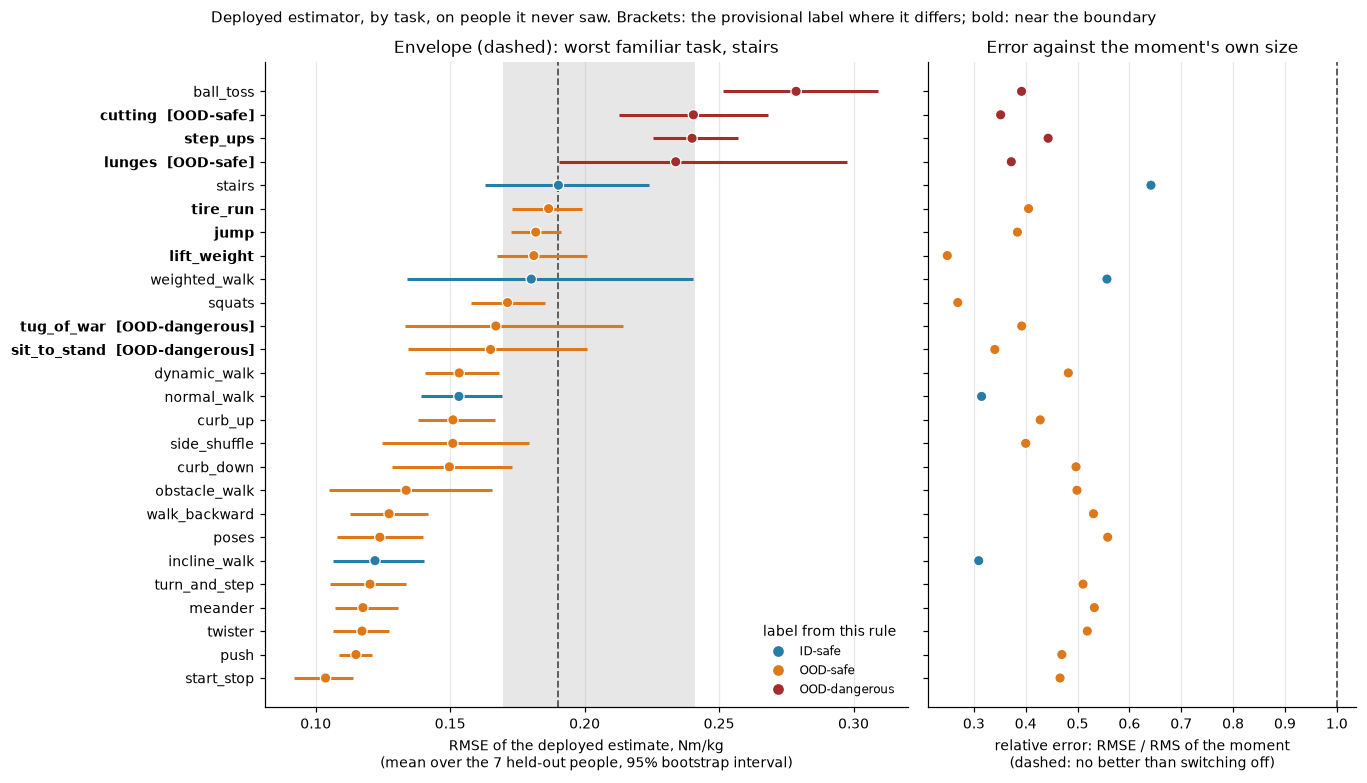

In [4]:
fig, axes = plt.subplots(1, 2, figsize = (12.5, 7.2), sharey = True, gridspec_kw = {'width_ratios': [3, 2]})
y = np.arange(len(table))
colors = table['label'].map(CLASS_C).to_numpy()
ax = axes[0]
ax.axvspan(env['envelope_lo'], env['envelope_hi'], color = '#bbb', alpha = .35, lw = 0)
ax.axvline(env['envelope'], color = '#555', lw = 1.2, ls = '--')
ax.hlines(y, table['rmse_lo'], table['rmse_hi'], color = colors, lw = 2)
ax.scatter(table['rmse'], y, s = 46, color = colors, edgecolor = 'white', linewidth = .8, zorder = 3)
ax.set_yticks(y, [f"{t}  [{p}]" if p != l else t for t, p, l in zip(table.index, table['provisional'], table['label'])])
for tick, near in zip(ax.get_yticklabels(), table['near_boundary']):
    tick.set_fontweight('bold' if near else 'normal')
ax.set(xlabel = 'RMSE of the deployed estimate, Nm/kg\n(mean over the 7 held-out people, 95% bootstrap interval)',
       title = f"Envelope (dashed): worst familiar task, {env['envelope_task']}")
ax.grid(axis = 'x', alpha = .3)
ax = axes[1]
ax.axvline(1, color = '#555', lw = 1.2, ls = '--')
ax.scatter(table['relative_error'], y, s = 46, color = colors, edgecolor = 'white', linewidth = .8, zorder = 3)
ax.set(xlabel = 'relative error: RMSE / RMS of the moment\n(dashed: no better than switching off)', title = 'Error against the moment\'s own size')
ax.grid(axis = 'x', alpha = .3)
handles = [plt.Line2D([], [], marker = 'o', ls = '', color = c, label = k) for k, c in CLASS_C.items()]
axes[0].legend(handles = handles, title = 'label from this rule', fontsize = 8, frameon = False, loc = 'lower right')
fig.suptitle('Deployed estimator, by task, on people it never saw. Brackets: the provisional label where it differs; '
             'bold: near the boundary', fontsize = 10)
plt.tight_layout(); fig.savefig(FIG_DIR / '04_estimator_labels.png', dpi = 160); plt.show()

In [5]:
from scipy.stats import spearmanr
rho_abs, rho_rel = spearmanr(table['rmse'], table['rms_moment']), spearmanr(table['relative_error'], table['rms_moment'])
print(f'across the 26 tasks: RMSE rises with the moment\'s size (Spearman rho {rho_abs.statistic:.2f}, p {rho_abs.pvalue:.0e}); '
      f'relative error falls with it (rho {rho_rel.statistic:.2f}, p {rho_rel.pvalue:.0e})')
print('relative error, unfamiliar tasks: {:.2f} to {:.2f}; familiar tasks: {:.2f} to {:.2f}'.format(
    *table.loc[~table.familiar, 'relative_error'].agg(['min', 'max']), *table.loc[table.familiar, 'relative_error'].agg(['min', 'max'])))

across the 26 tasks: RMSE rises with the moment's size (Spearman rho 0.81, p 4e-07); relative error falls with it (rho -0.82, p 3e-07)
relative error, unfamiliar tasks: 0.25 to 0.56; familiar tasks: 0.31 to 0.64


## 3. Against the provisional labels

In [6]:
unfamiliar = table[~table['familiar']]
display(pd.crosstab(unfamiliar['provisional'], unfamiliar['label'], margins = True))
changed = unfamiliar[unfamiliar['label'] != unfamiliar['provisional']]
print('tasks whose label changes:')
display(changed[['provisional', 'label', 'near_boundary', 'rmse', 'relative_error', 'wrong_direction_pct']].round(3))

label,OOD-dangerous,OOD-safe,All
provisional,,,
OOD-dangerous,2,2,4
OOD-safe,2,16,18
All,4,18,22


tasks whose label changes:


,provisional,label,near_boundary,rmse,relative_error,wrong_direction_pct
task,,,,,,
sit_to_stand,OOD-dangerous,OOD-safe,True,0.165,0.340,1.573
tug_of_war,OOD-dangerous,OOD-safe,True,0.167,0.392,5.247
lunges,OOD-safe,OOD-dangerous,True,0.234,0.372,8.577
cutting,OOD-safe,OOD-dangerous,True,0.240,0.352,5.015


## 4. Sensitivity: adding the three returning participants

BT01, BT02 and BT13 were recorded in Phase 1–2 too, so the deployed estimator was trained on them in another
session. Adding them gives ten people; a label that flips here rests on the rule's margin rather than on the data.

In [7]:
errors_all = el.get_person_task_errors(el.load_pairs(inv, HELD_OUT + RETURNING))
table_all, env_all = el.get_task_table(errors_all, FAMILIAR, np.random.default_rng(SEED))
print(f"envelope with ten people: {env_all['envelope']:.3f} Nm/kg ({env_all['envelope_task']})")
both = table[['label', 'near_boundary', 'rmse']].join(table_all[['label', 'rmse']], rsuffix = ', ten people')
flips = both[both['label'] != both['label, ten people']]
print(f"{len(flips)} of {(~table['familiar']).sum()} unfamiliar tasks change label with the returning participants added")
display(flips.round(3))

envelope with ten people: 0.186 Nm/kg (stairs)
3 of 22 unfamiliar tasks change label with the returning participants added


,label,near_boundary,rmse,"label, ten people","rmse, ten people"
task,,,,,
tug_of_war,OOD-safe,True,0.167,OOD-dangerous,0.187
jump,OOD-safe,True,0.182,OOD-dangerous,0.196
tire_run,OOD-safe,True,0.187,OOD-dangerous,0.191


## 5. What this shows

**For the controller labels**

- **The deployed estimator's error supports one firm OOD-dangerous label, the ball toss.** Step-ups, cutting and
  lunges are above the envelope but within its uncertainty; sit-to-stand and tug of war, labelled dangerous by hand,
  are inside it.
- **Error alone is a weak basis for "dangerous".** Measured against the moment's size or against switching off, the
  estimator handles every unfamiliar task about as well as familiar walking. If sit-to-stand or tug of war should stay
  dangerous, the reason is something the error cannot see (fall risk, an external load, wrong-direction assistance), and
  the thesis should say which.
- **The labels should come from the estimator the exoskeleton will run.** This estimator used hip and knee encoders and
  thigh, shank and foot IMUs. The project's fallback sees the hip encoder and thigh IMU only, and notebook 01 (6.2) found
  every one of those channels weak on standing and unstructured tasks. The same rule applied to that estimator's
  held-out error is the decisive version; this notebook is its optimistic bound.
- **Until then, keep the provisional labels for the awareness models** (`nature_data.OOD_DANGEROUS_TASKS`), so results
  stay comparable, and report the derived labels beside them.

**Limits**

- Seven people. The envelope rests on one familiar task (stairs) whose own interval spans 0.169 to 0.241 Nm/kg.
- The moment is zero-phase filtered and the estimate is realigned for its delay (notebook 01, 5.2 and 5.5); a causal
  comparison would raise every error somewhat.
- Both legs are pooled per person; tasks with long rests between repetitions are scored on in-task samples only.